# Автоматизация подбора персонала
## Векторный поиск + LLM-реранжирование

**Пайплайн:**
1. Загрузка и парсинг данных (вакансии, резюме, аннотации экспертов)
2. Построение эмбеддингов (Sentence-Transformers / OpenAI)
3. Векторный поиск (FAISS / Pinecone)
4. LLM-реранжирование (Claude / OpenAI GPT)
5. Оценка качества (Kendall τ, Spearman ρ, NDCG@k, Top-k Accuracy, MRR)
6. Сравнительный анализ и визуализация

---

## 1. Установка зависимостей

In [ ]:
%%capture
!pip install sentence-transformers faiss-cpu python-docx anthropic openai scikit-learn scipy numpy pandas matplotlib seaborn tqdm

## 2. Импорты и настройки

In [ ]:
import os
import re
import csv
import json
import time
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from typing import List, Dict, Tuple, Optional

import faiss
from docx import Document as DocxDocument
from sentence_transformers import SentenceTransformer
from scipy.stats import kendalltau, spearmanr
from sklearn.metrics import ndcg_score
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

# Логирование
logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s')
logger = logging.getLogger(__name__)

def log_info(tag, msg):
    logger.info(f'[{tag}] {msg}')

print('✅ Все библиотеки импортированы')

✅ Все библиотеки импортированы


## 3. API-ключи

Для LLM-реранжирования нужен ключ Anthropic (Claude) **или** OpenAI.
Оставьте пустым, если хотите использовать только векторный поиск без реранжирования.

In [ ]:
# @title Настройка API-ключей { display-mode: "form" }

ANTHROPIC_API_KEY = ''  # @param {type:"string"}
OPENAI_API_KEY = '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'     # @param {type:"string"}

# Автоопределение провайдера по формату ключа
USE_CLAUDE = bool(ANTHROPIC_API_KEY)
USE_OPENROUTER = bool(OPENAI_API_KEY) and OPENAI_API_KEY.startswith('sk-or-')
USE_OPENAI_NATIVE = bool(OPENAI_API_KEY) and not OPENAI_API_KEY.startswith('sk-or-') and not USE_CLAUDE
USE_OPENAI_LLM = USE_OPENROUTER or USE_OPENAI_NATIVE
USE_LLM = USE_CLAUDE or USE_OPENAI_LLM

if USE_CLAUDE:
    import anthropic
    client_llm = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)
    LLM_PROVIDER = 'claude'
    print('✅ Anthropic Claude — подключён')

elif USE_OPENROUTER:
    from openai import OpenAI
    client_llm = OpenAI(
        api_key=OPENAI_API_KEY,
        base_url='https://openrouter.ai/api/v1'
    )
    LLM_PROVIDER = 'openrouter'
    print('✅ OpenRouter — подключён (ключ sk-or-* обнаружен)')
    print('   Будет использована модель через OpenRouter API')

elif USE_OPENAI_NATIVE:
    from openai import OpenAI
    client_llm = OpenAI(api_key=OPENAI_API_KEY)
    LLM_PROVIDER = 'openai'
    print('✅ OpenAI GPT — подключён')

else:
    client_llm = None
    LLM_PROVIDER = None
    print('⚠️ LLM не настроен — будет работать только векторный поиск (без реранжирования)')
    print('   Поддерживаемые ключи:')
    print('   • Anthropic:   sk-ant-... → ANTHROPIC_API_KEY')
    print('   • OpenAI:      sk-...     → OPENAI_API_KEY')
    print('   • OpenRouter:  sk-or-...  → OPENAI_API_KEY')

✅ OpenRouter — подключён (ключ sk-or-* обнаружен)
   Будет использована модель через OpenRouter API


## 4. Загрузка данных с Google Drive

In [ ]:
from google.colab import drive
log_info('DATA', 'Начало загрузки данных')
drive.mount('/content/drive')

DATA_FOLDER = '/content/drive/MyDrive/vacancy-resume-matching-dataset'
VACANCIES_PATH = os.path.join(DATA_FOLDER, '5_vacancies.csv')
ANNOTATIONS_PATH = os.path.join(DATA_FOLDER, 'annotations-for-the-first-30-vacancies.txt')

# Папки с резюме
CV_FOLDER_TRAIN = os.path.join(DATA_FOLDER, 'CV')                     # Аннотированные (1-30)
CV_FOLDER_TEST  = os.path.join(DATA_FOLDER, 'CV', 'NotAnnotated')     # Не аннотированные (31-65)

# Проверка
for p in [VACANCIES_PATH, ANNOTATIONS_PATH, CV_FOLDER_TRAIN]:
    assert os.path.exists(p), f'Не найден: {p}'
print('Все пути валидны')

Mounted at /content/drive
Все пути валидны


## 5. Парсинг вакансий

Загружаем 5 вакансий из CSV-файла.

In [ ]:
def load_vacancies(path: str) -> pd.DataFrame:
    """Загрузка вакансий из CSV. Пробует разные разделители."""
    for sep in [',', ';', '\t', '|']:
        try:
            df = pd.read_csv(path, sep=sep, encoding='utf-8')
            if len(df.columns) > 1:
                break
        except Exception:
            continue
    else:
        df = pd.read_csv(path, encoding='utf-8')

    log_info('VACANCIES', f'Загружено {len(df)} вакансий, столбцы: {list(df.columns)}')
    return df

vacancies_df = load_vacancies(VACANCIES_PATH)
display(vacancies_df.head())

# Формируем текстовое представление каждой вакансии
# (объединяем все столбцы в одну строку)
def vacancy_to_text(row: pd.Series) -> str:
    parts = []
    for col in row.index:
        val = str(row[col]).strip()
        if val and val.lower() != 'nan':
            parts.append(f'{col}: {val}')
    return '\n'.join(parts)

vacancy_texts = {}
for idx, row in vacancies_df.iterrows():
    vid = idx + 1  # ID вакансии: 1..5
    vacancy_texts[vid] = vacancy_to_text(row)

print(f'\n Пример текста вакансии #{1}:')
print(vacancy_texts[1][:500], '...' if len(vacancy_texts[1]) > 500 else '')

,id,job_description,job_title,uid
0,8,Primary Purpose: Development and maintenance o...,Software Developer - .Net,e3f78c8c36195e4438286bb9395085a0
1,37,Precision is king when it comes to the work yo...,Remote Software Developer,708584f2d49cb195c9fc9d7bee36e699
2,90,A Full-time position at a financial technology...,Junior Level Software Developer (1-4 years exp...,72fafc405b891220ce78df7fd4e72a80
3,207,"Minimum Required Skills: LAMP, Drupal, Elastic...",Backend Software Developer,5eb96f825590e690d76930c52b9100de
4,499,"Minimum Required Skills: Java, C#, SQL, HTTPS,...",Software Developer,296f9b55a3a3eed93ad08924274f2eba



 Пример текста вакансии #1:
id: 8
job_description: Primary Purpose: Development and maintenance of software applications built using Microsoft stack. Essential Duties and Responsibilities: Following is a summary of the essential functions for this job. Other duties may be performed, both major and minor, which are not mentioned below. Specific activities may change from time to time. Design, develop and test software applications Maintain systems by identifying and correcting software defects Create technical specification ...


## 6. Парсинг резюме

Извлекаем текст из DOCX-файлов.

In [ ]:
def extract_text_from_docx(path: str) -> str:
    """Извлечение текста из .docx файла."""
    try:
        doc = DocxDocument(path)
        paragraphs = [p.text.strip() for p in doc.paragraphs if p.text.strip()]
        # Также извлекаем текст из таблиц
        for table in doc.tables:
            for row in table.rows:
                row_text = ' | '.join(cell.text.strip() for cell in row.cells if cell.text.strip())
                if row_text:
                    paragraphs.append(row_text)
        return '\n'.join(paragraphs)
    except Exception as e:
        logger.warning(f'Ошибка чтения {path}: {e}')
        return ''

def load_resumes(cv_folder: str, id_range: range) -> Dict[int, str]:
    """Загрузка резюме из папки."""
    resumes = {}
    for rid in tqdm(id_range, desc='Загрузка резюме'):
        path = os.path.join(cv_folder, f'{rid}.docx')
        if os.path.exists(path):
            text = extract_text_from_docx(path)
            if text:
                resumes[rid] = text
            else:
                logger.warning(f'Пустое резюме: {rid}')
        else:
            logger.warning(f'Файл не найден: {path}')
    return resumes

# Загружаем размеченные резюме (1-30)
log_info('CV', 'Загрузка аннотированных резюме (1-30)')
resumes_annotated = load_resumes(CV_FOLDER_TRAIN, range(1, 31))

# Загружаем неразмеченные резюме (31-65)
log_info('CV', 'Загрузка неаннотированных резюме (31-65)')
resumes_unannotated = load_resumes(CV_FOLDER_TEST, range(31, 66))

# Объединяем
all_resumes = {**resumes_annotated, **resumes_unannotated}

print(f'\n Загружено: {len(resumes_annotated)} аннотированных, '
      f'{len(resumes_unannotated)} неаннотированных, '
      f'{len(all_resumes)} всего')
print(f'\n Пример резюме #{1} (первые 300 символов):')
print(list(resumes_annotated.values())[0][:300])

Загрузка резюме:   0%|          | 0/30 [00:00<?, ?it/s]

Загрузка резюме:   0%|          | 0/35 [00:00<?, ?it/s]


 Загружено: 30 аннотированных, 35 неаннотированных, 65 всего

 Пример резюме #1 (первые 300 символов):
****************
Java full stack developer
(60% – IN JAVA BACKEND DEVELOPMENT AND 40% – IN WEB FRONTEND)
3+ years of experience FullStack development and 5+ total experience in software development
phone**********	 		linkedIn
location Bat Yam     		email
Professional Skills
Programming languages: Ja


## 7. Парсинг аннотаций экспертов

Два HR-специалиста ранжировали вакансии для каждого резюме.
Формат: для каждого резюме указан порядок вакансий от наиболее до наименее подходящей.

In [ ]:
def parse_annotations(path: str) -> Dict:
    """
    Парсинг файла аннотаций.
    Возвращает dict: {resume_id: {'a1': [v_id, ...], 'a2': [v_id, ...]}}
    где списки — порядок вакансий от лучшей к худшей.
    """
    annotations = {}

    with open(path, 'r', encoding='utf-8') as f:
        content = f.read()

    log_info('ANNOT', f'Файл аннотаций: {len(content)} символов')
    print('Первые 500 символов файла аннотаций:')
    print(content[:500])
    print('---')

    lines = [l.strip() for l in content.strip().split('\n') if l.strip()]

    # Стратегия 1: Табличный формат (резюме_id, annotator1_rank, annotator2_rank)
    # Стратегия 2: Блочный формат (резюме_id: [ранги])
    # Стратегия 3: CSV-подобный

    # Пробуем определить формат автоматически
    # Ищем числа в строках
    parsed = False

    # Попытка: каждая строка = resume_id, a1_rankings, a2_rankings
    # Например: "1\t3,1,5,2,4\t2,1,5,3,4"
    try:
        for line in lines:
            # Пропускаем заголовки
            if any(h in line.lower() for h in ['resume', 'резюме', 'cv', 'annotator', 'аннотатор', '#']):
                continue

            # Разделяем по табуляции или множественным пробелам
            parts = re.split(r'[\t;|]+|\s{2,}', line)
            parts = [p.strip() for p in parts if p.strip()]

            if len(parts) < 2:
                # Может быть через запятые
                parts = line.split(',')
                parts = [p.strip() for p in parts if p.strip()]

            if len(parts) >= 3:
                # Первый элемент — ID резюме
                try:
                    rid = int(re.search(r'\d+', parts[0]).group())
                except (AttributeError, ValueError):
                    continue

                if rid < 1 or rid > 30:
                    continue

                # Оставшиеся — ранги двух аннотаторов
                # Может быть: [rid, "3 1 5 2 4", "2 1 5 3 4"]
                # или: [rid, 3, 1, 5, 2, 4, 2, 1, 5, 3, 4]
                remaining = parts[1:]

                # Извлекаем все числа из оставшихся частей
                all_nums = []
                for p in remaining:
                    nums = re.findall(r'\d+', p)
                    all_nums.extend([int(n) for n in nums])

                if len(all_nums) == 10:
                    # 5 + 5 рангов
                    a1 = all_nums[:5]
                    a2 = all_nums[5:]
                    annotations[rid] = {'a1': a1, 'a2': a2}
                    parsed = True
                elif len(all_nums) == 5:
                    # Только один аннотатор или усреднённые
                    annotations[rid] = {'a1': all_nums, 'a2': all_nums}
                    parsed = True

    except Exception as e:
        logger.warning(f'Ошибка парсинга: {e}')

    if not parsed or len(annotations) < 5:
        # Запасная стратегия: считываем все числа блоками
        logger.warning('Основной парсер не сработал, пробуем альтернативный...')
        all_numbers = [int(n) for n in re.findall(r'\d+', content)]
        log_info('ANNOT', f'Найдено {len(all_numbers)} чисел в файле')

        # Пробуем формат: resume_id, 5 рангов аннотатор1, 5 рангов аннотатор2 = 11 чисел на строку
        if len(all_numbers) >= 30 * 11:
            for i in range(30):
                offset = i * 11
                rid = all_numbers[offset]
                a1 = all_numbers[offset+1:offset+6]
                a2 = all_numbers[offset+6:offset+11]
                annotations[rid] = {'a1': a1, 'a2': a2}
        # Формат: resume_id + 5 рангов = 6 чисел (один аннотатор / усреднённые)
        elif len(all_numbers) >= 30 * 6:
            for i in range(30):
                offset = i * 6
                rid = all_numbers[offset]
                ranks = all_numbers[offset+1:offset+6]
                annotations[rid] = {'a1': ranks, 'a2': ranks}

    log_info('ANNOT', f'Распарсено аннотаций: {len(annotations)}')

    if annotations:
        sample_rid = list(annotations.keys())[0]
        print(f'\nПример аннотации для резюме #{sample_rid}:')
        print(f'  Аннотатор 1: {annotations[sample_rid]["a1"]}')
        print(f'  Аннотатор 2: {annotations[sample_rid]["a2"]}')

    return annotations

annotations = parse_annotations(ANNOTATIONS_PATH)
print(f'\n Загружено аннотаций для {len(annotations)} резюме')

Первые 500 символов файла аннотаций:
Ground truth for the first 30 vacancies (files numbered 1-30) against 5 vacancies 
given in the "5_vacancies.csv" file according to the instructions received from a senior HR specialist that appear
in the "annotation_instructions.docx" file.

Annotations by two independent annotators, for every CV vacancies 1-5 are ranked from the best (place 1 in the annotation array) to the worst (place 5 in the annotation array).
Total 30 arrays of 5 ranks for every annotator.

ANNOTATOR_1_RANKINGS=[[2,1,4,3,
---

Пример аннотации для резюме #30:
  Аннотатор 1: [1, 30, 5, 5, 1]
  Аннотатор 2: [5, 1, 5, 30, 5]

 Загружено аннотаций для 7 резюме


## 8. Формирование эталона (Ground Truth)

Объединяем оценки двух аннотаторов в усреднённый ранг.

In [ ]:
def build_ground_truth(annotations: Dict) -> Dict[int, List[int]]:
    """
    Строит эталонное ранжирование: усреднённый ранг двух аннотаторов.
    Возвращает {resume_id: [vacancy_id_best, ..., vacancy_id_worst]}
    """
    ground_truth = {}

    for rid, ann in annotations.items():
        a1 = ann['a1']  # Порядок вакансий (от лучшей)
        a2 = ann['a2']

        # Преобразуем порядок в ранги: rank[vacancy_id] = position (1=best)
        # Если a1 = [3,1,5,2,4] значит вакансия 3 на 1-м месте, вакансия 1 на 2-м и т.д.
        rank1 = {v: pos + 1 for pos, v in enumerate(a1)}
        rank2 = {v: pos + 1 for pos, v in enumerate(a2)}

        # Усредняем ранги
        all_vids = set(list(rank1.keys()) + list(rank2.keys()))
        avg_ranks = {}
        for v in all_vids:
            r1 = rank1.get(v, len(a1) + 1)
            r2 = rank2.get(v, len(a2) + 1)
            avg_ranks[v] = (r1 + r2) / 2

        # Сортируем по среднему рангу (меньше = лучше)
        sorted_vids = sorted(avg_ranks.keys(), key=lambda v: avg_ranks[v])
        ground_truth[rid] = sorted_vids

    return ground_truth

ground_truth = build_ground_truth(annotations)

if ground_truth:
    sample = list(ground_truth.items())[:3]
    print('Примеры эталонного ранжирования (вакансии от лучшей к худшей):')
    for rid, ranking in sample:
        print(f'  Резюме #{rid}: {ranking}')

print(f'\n Эталон построен для {len(ground_truth)} резюме')

Примеры эталонного ранжирования (вакансии от лучшей к худшей):
  Резюме #30: [30, 1, 5]
  Резюме #1: [4, 2, 3, 5, 1]
  Резюме #5: [1, 2, 4, 5, 3]

 Эталон построен для 7 резюме


## 9. Согласованность аннотаторов (Inter-Annotator Agreement)

In [ ]:
def compute_annotator_agreement(annotations: Dict) -> Dict:
    """Вычисляет согласованность между двумя аннотаторами."""
    tau_scores = []
    rho_scores = []

    for rid, ann in annotations.items():
        a1 = ann['a1']
        a2 = ann['a2']

        if a1 == a2:
            tau_scores.append(1.0)
            rho_scores.append(1.0)
            continue

        # Приводим к рангам
        rank1 = [0] * (max(a1) + 1)
        rank2 = [0] * (max(a2) + 1)
        for pos, v in enumerate(a1):
            if v < len(rank1):
                rank1[v] = pos + 1
        for pos, v in enumerate(a2):
            if v < len(rank2):
                rank2[v] = pos + 1

        # Используем только общие вакансии
        common = set(a1) & set(a2)
        if len(common) < 2:
            continue

        r1 = [a1.index(v) + 1 for v in sorted(common)]
        r2 = [a2.index(v) + 1 for v in sorted(common)]

        tau, _ = kendalltau(r1, r2)
        rho, _ = spearmanr(r1, r2)

        if not np.isnan(tau):
            tau_scores.append(tau)
        if not np.isnan(rho):
            rho_scores.append(rho)

    result = {
        'kendall_tau_mean': np.mean(tau_scores) if tau_scores else 0,
        'kendall_tau_std': np.std(tau_scores) if tau_scores else 0,
        'spearman_rho_mean': np.mean(rho_scores) if rho_scores else 0,
        'spearman_rho_std': np.std(rho_scores) if rho_scores else 0,
        'n_valid': len(tau_scores)
    }
    return result

if annotations:
    iaa = compute_annotator_agreement(annotations)
    print(' Согласованность аннотаторов:')
    print(f"  Kendall's τ:  {iaa['kendall_tau_mean']:.3f} ± {iaa['kendall_tau_std']:.3f}")
    print(f"  Spearman's ρ: {iaa['spearman_rho_mean']:.3f} ± {iaa['spearman_rho_std']:.3f}")
    print(f'  Оценено пар: {iaa["n_valid"]}')
else:
    print(' Нет аннотаций для расчёта согласованности')

 Согласованность аннотаторов:
  Kendall's τ:  0.322 ± 0.571
  Spearman's ρ: 0.283 ± 0.667
  Оценено пар: 6


## 10. Построение эмбеддингов

Используем многоязычную модель `paraphrase-multilingual-MiniLM-L12-v2` для поддержки русского языка.
Модель бесплатная и работает локально — API-ключ не нужен.

In [ ]:
# @title Выбор модели эмбеддингов { display-mode: "form" }
EMBEDDING_MODEL = 'paraphrase-multilingual-mpnet-base-v2'  # @param ['paraphrase-multilingual-MiniLM-L12-v2', 'paraphrase-multilingual-mpnet-base-v2', 'distiluse-base-multilingual-cased-v2']

log_info('EMB', f'Загрузка модели: {EMBEDDING_MODEL}')
embedder = SentenceTransformer(EMBEDDING_MODEL)
EMBEDDING_DIM = embedder.get_sentence_embedding_dimension()
print(f' Модель загружена. Размерность: {EMBEDDING_DIM}')

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

 Модель загружена. Размерность: 768


In [ ]:
# Строим эмбеддинги для всех резюме и вакансий
log_info('EMB', 'Построение эмбеддингов для вакансий...')
vacancy_embeddings = {}
for vid, text in vacancy_texts.items():
    vacancy_embeddings[vid] = embedder.encode(text, normalize_embeddings=True)
print(f'  Вакансий: {len(vacancy_embeddings)}')

log_info('EMB', 'Построение эмбеддингов для резюме...')
resume_embeddings = {}
resume_ids_ordered = sorted(all_resumes.keys())

# Батчируем для скорости
batch_texts = [all_resumes[rid] for rid in resume_ids_ordered]
batch_embs = embedder.encode(batch_texts, normalize_embeddings=True,
                              show_progress_bar=True, batch_size=16)

for rid, emb in zip(resume_ids_ordered, batch_embs):
    resume_embeddings[rid] = emb

print(f'  Резюме: {len(resume_embeddings)}')
print(' Все эмбеддинги построены')

  Вакансий: 5


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  Резюме: 65
 Все эмбеддинги построены


## 11. Векторный поиск (FAISS)

Строим FAISS-индекс для быстрого поиска ближайших резюме по вектору вакансии.

In [ ]:
# Собираем матрицу эмбеддингов резюме
resume_matrix = np.array([resume_embeddings[rid] for rid in resume_ids_ordered]).astype('float32')

# Создаём FAISS-индекс (Inner Product для нормализованных векторов = cosine similarity)
index = faiss.IndexFlatIP(EMBEDDING_DIM)
index.add(resume_matrix)

log_info('FAISS', f'Индекс построен: {index.ntotal} векторов, dim={EMBEDDING_DIM}')

def search_resumes(vacancy_id: int, top_k: int = 10) -> List[Tuple[int, float]]:
    """
    Поиск top_k ближайших резюме для вакансии.
    Возвращает [(resume_id, score), ...] в порядке убывания score.
    """
    query = vacancy_embeddings[vacancy_id].reshape(1, -1).astype('float32')
    scores, indices = index.search(query, top_k)
    results = []
    for score, idx in zip(scores[0], indices[0]):
        if idx < len(resume_ids_ordered):
            results.append((resume_ids_ordered[idx], float(score)))
    return results

# Тест: ищем топ-5 резюме для каждой вакансии
print('\n Результаты векторного поиска (топ-5 для каждой вакансии):')
for vid in sorted(vacancy_texts.keys()):
    results = search_resumes(vid, top_k=5)
    rids = [r[0] for r in results]
    scores = [f'{r[1]:.3f}' for r in results]
    print(f'  Вакансия #{vid}: резюме {rids} (scores: {scores})')


 Результаты векторного поиска (топ-5 для каждой вакансии):
  Вакансия #1: резюме [25, 36, 65, 26, 38] (scores: ['0.490', '0.466', '0.444', '0.419', '0.405'])
  Вакансия #2: резюме [26, 46, 47, 48, 12] (scores: ['0.377', '0.356', '0.345', '0.321', '0.307'])
  Вакансия #3: резюме [38, 34, 52, 21, 31] (scores: ['0.561', '0.525', '0.525', '0.522', '0.504'])
  Вакансия #4: резюме [25, 3, 65, 34, 51] (scores: ['0.560', '0.466', '0.457', '0.454', '0.441'])
  Вакансия #5: резюме [34, 31, 1, 3, 25] (scores: ['0.556', '0.540', '0.515', '0.506', '0.503'])


## 12. Ранжирование по результатам Retrieval

Для каждого аннотированного резюме определяем порядок вакансий по cosine similarity.

In [ ]:
def rank_vacancies_by_retrieval(resume_id: int) -> List[int]:
    """
    Ранжирует вакансии для резюме по cosine similarity.
    Возвращает список vacancy_id от наиболее подходящей к наименее.
    """
    if resume_id not in resume_embeddings:
        return []

    r_emb = resume_embeddings[resume_id]
    scores = []
    for vid in sorted(vacancy_texts.keys()):
        v_emb = vacancy_embeddings[vid]
        sim = float(np.dot(r_emb, v_emb))  # cosine sim (нормализованные)
        scores.append((vid, sim))

    scores.sort(key=lambda x: x[1], reverse=True)
    return [vid for vid, _ in scores]

# Ранжируем все аннотированные резюме
retrieval_rankings = {}
for rid in sorted(resumes_annotated.keys()):
    retrieval_rankings[rid] = rank_vacancies_by_retrieval(rid)

print(' Примеры ранжирования (Retrieval vs Ground Truth):')
for rid in list(ground_truth.keys())[:5]:
    gt = ground_truth.get(rid, [])
    ret = retrieval_rankings.get(rid, [])
    print(f'  Резюме #{rid}: GT={gt}, Retrieval={ret}')

print(f'\n Ранжирование построено для {len(retrieval_rankings)} резюме')

 Примеры ранжирования (Retrieval vs Ground Truth):
  Резюме #30: GT=[30, 1, 5], Retrieval=[4, 3, 1, 2, 5]
  Резюме #1: GT=[4, 2, 3, 5, 1], Retrieval=[5, 4, 3, 1, 2]
  Резюме #5: GT=[1, 2, 4, 5, 3], Retrieval=[4, 5, 3, 1, 2]
  Резюме #3: GT=[1, 5, 4, 2, 3], Retrieval=[5, 4, 1, 3, 2]
  Резюме #2: GT=[1, 4, 5, 2, 3], Retrieval=[5, 4, 3, 1, 2]

 Ранжирование построено для 30 резюме


## 13. LLM-реранжирование

Отправляем текст вакансий и резюме в LLM для более точного ранжирования.

In [ ]:
RERANKER_SYSTEM_PROMPT = """Ты — эксперт по подбору персонала (HR).
Тебе дан текст резюме кандидата и список из нескольких вакансий.
Оцени, насколько резюме подходит к КАЖДОЙ вакансии по шкале от 0 до 100.

Учитывай:
- Опыт работы и его релевантность
- Навыки и компетенции
- Образование
- Уровень позиции
- Отрасль

Ответь СТРОГО в формате JSON (без markdown-блоков, без пояснений):
{"scores": {"1": <score>, "2": <score>, "3": <score>, "4": <score>, "5": <score>}}

Где ключи — номера вакансий, значения — оценки от 0 до 100."""


# Выбор модели в зависимости от провайдера
LLM_MODELS = {
    'claude':     'claude-sonnet-4-20250514',
    'openai':     'gpt-4o-mini',
    'openrouter': 'anthropic/claude-sonnet-4',  # Или любая другая модель из OpenRouter
}


def build_reranker_prompt(resume_id: int, resume_text: str,
                          vacancy_texts: Dict[int, str]) -> str:
    """Формирует промпт для LLM-реранжировщика."""
    max_resume_len = 3000
    max_vacancy_len = 1500

    prompt = f'РЕЗЮМЕ КАНДИДАТА (ID: {resume_id}):\n'
    prompt += resume_text[:max_resume_len]
    if len(resume_text) > max_resume_len:
        prompt += '\n[...текст обрезан...]'
    prompt += '\n\n'

    prompt += 'ВАКАНСИИ:\n'
    for vid in sorted(vacancy_texts.keys()):
        vtext = vacancy_texts[vid][:max_vacancy_len]
        prompt += f'\n--- Вакансия #{vid} ---\n{vtext}\n'

    prompt += '\nОцени соответствие резюме каждой вакансии (0-100). Ответ в JSON.'
    return prompt


def call_llm_reranker(prompt: str) -> Optional[Dict[int, float]]:
    """Вызывает LLM и парсит JSON-ответ со скорами."""
    text = ''
    try:
        if LLM_PROVIDER == 'claude':
            # Прямой вызов Anthropic API
            response = client_llm.messages.create(
                model=LLM_MODELS['claude'],
                max_tokens=500,
                system=RERANKER_SYSTEM_PROMPT,
                messages=[{'role': 'user', 'content': prompt}]
            )
            text = response.content[0].text

        elif LLM_PROVIDER in ('openai', 'openrouter'):
            # OpenAI-совместимый API (нативный OpenAI или OpenRouter)
            model = LLM_MODELS[LLM_PROVIDER]
            response = client_llm.chat.completions.create(
                model=model,
                max_tokens=500,
                messages=[
                    {'role': 'system', 'content': RERANKER_SYSTEM_PROMPT},
                    {'role': 'user', 'content': prompt}
                ]
            )
            text = response.choices[0].message.content
        else:
            return None

        # Парсим JSON
        text = text.strip()
        # Убираем markdown code blocks если есть
        text = re.sub(r'^```json\s*', '', text)
        text = re.sub(r'\s*```$', '', text)
        text = text.strip()

        data = json.loads(text)
        scores = data.get('scores', data)
        return {int(k): float(v) for k, v in scores.items()}

    except json.JSONDecodeError as e:
        logger.warning(f'JSON parse error: {e}\nResponse: {text[:200]}')
        # Пробуем извлечь числа регуляркой
        nums = re.findall(r'"(\d+)"\s*:\s*(\d+\.?\d*)', text)
        if nums:
            return {int(k): float(v) for k, v in nums}
        return None

    except Exception as e:
        logger.warning(f'LLM error: {e}')
        return None


print(' Функции реранжирования определены')
if LLM_PROVIDER:
    model_name = LLM_MODELS.get(LLM_PROVIDER, '?')
    print(f'   Провайдер: {LLM_PROVIDER}')
    print(f'   Модель:    {model_name}')
else:
    print('  LLM не доступен — реранжирование будет пропущено')

 Функции реранжирования определены
   Провайдер: openrouter
   Модель:    anthropic/claude-sonnet-4


In [ ]:
# Запускаем LLM-реранжирование для аннотированных резюме
reranker_rankings = {}
reranker_scores_raw = {}

if USE_LLM:
    log_info('RERANK', 'Запуск LLM-реранжирования для аннотированных резюме...')

    annotated_rids = sorted(resumes_annotated.keys())

    for i, rid in enumerate(tqdm(annotated_rids, desc='LLM Reranking')):
        if rid not in all_resumes:
            continue

        prompt = build_reranker_prompt(rid, all_resumes[rid], vacancy_texts)
        scores = call_llm_reranker(prompt)

        if scores:
            reranker_scores_raw[rid] = scores
            # Сортируем вакансии по скору (больше = лучше)
            sorted_vids = sorted(scores.keys(), key=lambda v: scores[v], reverse=True)
            reranker_rankings[rid] = sorted_vids
        else:
            logger.warning(f'Не удалось получить скоры для резюме #{rid}')

        # Rate limiting
        if (i + 1) % 5 == 0:
            time.sleep(1)

    print(f'\n Реранжировано: {len(reranker_rankings)} из {len(annotated_rids)} резюме')

    # Примеры
    print('\n Примеры (GT vs Retrieval vs LLM Reranker):')
    for rid in list(ground_truth.keys())[:5]:
        gt = ground_truth.get(rid, [])
        ret = retrieval_rankings.get(rid, [])
        rer = reranker_rankings.get(rid, [])
        print(f'  Резюме #{rid}:')
        print(f'    GT:       {gt}')
        print(f'    Retrieval:{ret}')
        print(f'    Reranker: {rer}')
        if rid in reranker_scores_raw:
            print(f'    Scores:   {reranker_scores_raw[rid]}')
else:
    print('LLM-реранжирование пропущено (нет API-ключа)')

LLM Reranking:   0%|          | 0/30 [00:00<?, ?it/s]


 Реранжировано: 30 из 30 резюме

 Примеры (GT vs Retrieval vs LLM Reranker):
  Резюме #30:
    GT:       [30, 1, 5]
    Retrieval:[4, 3, 1, 2, 5]
    Reranker: [4, 1, 5, 2, 3]
    Scores:   {1: 35.0, 2: 25.0, 3: 20.0, 4: 65.0, 5: 30.0}
  Резюме #1:
    GT:       [4, 2, 3, 5, 1]
    Retrieval:[5, 4, 3, 1, 2]
    Reranker: [5, 3, 4, 1, 2]
    Scores:   {1: 45.0, 2: 35.0, 3: 75.0, 4: 55.0, 5: 85.0}
  Резюме #5:
    GT:       [1, 2, 4, 5, 3]
    Retrieval:[4, 5, 3, 1, 2]
    Reranker: [5, 4, 3, 2, 1]
    Scores:   {1: 25.0, 2: 45.0, 3: 75.0, 4: 85.0, 5: 90.0}
  Резюме #3:
    GT:       [1, 5, 4, 2, 3]
    Retrieval:[5, 4, 1, 3, 2]
    Reranker: [4, 5, 3, 1, 2]
    Scores:   {1: 45.0, 2: 35.0, 3: 75.0, 4: 85.0, 5: 80.0}
  Резюме #2:
    GT:       [1, 4, 5, 2, 3]
    Retrieval:[5, 4, 3, 1, 2]
    Reranker: [5, 3, 4, 2, 1]
    Scores:   {1: 25.0, 2: 45.0, 3: 75.0, 4: 60.0, 5: 85.0}


## 14. Метрики оценки качества

Сравниваем результаты Retrieval и Reranker с экспертным эталоном.

In [ ]:
def compute_ranking_metrics(ground_truth: Dict[int, List[int]],
                             predicted: Dict[int, List[int]],
                             n_vacancies: int = 5) -> Dict:
    """
    Вычисляет метрики ранжирования.

    Args:
        ground_truth: {resume_id: [vid_best, ..., vid_worst]}
        predicted:    {resume_id: [vid_best, ..., vid_worst]}
    """
    tau_scores = []
    rho_scores = []
    ndcg_1_scores = []
    ndcg_3_scores = []
    ndcg_5_scores = []
    top1_correct = []
    top3_correct = []
    reciprocal_ranks = []

    common_rids = set(ground_truth.keys()) & set(predicted.keys())

    for rid in sorted(common_rids):
        gt_order = ground_truth[rid]
        pred_order = predicted[rid]

        if not gt_order or not pred_order:
            continue

        # Ранги: позиция каждой вакансии (1 = лучшая)
        gt_ranks = {v: pos + 1 for pos, v in enumerate(gt_order)}
        pred_ranks = {v: pos + 1 for pos, v in enumerate(pred_order)}

        # Общие вакансии
        common_v = sorted(set(gt_ranks.keys()) & set(pred_ranks.keys()))
        if len(common_v) < 2:
            continue

        gt_r = [gt_ranks[v] for v in common_v]
        pred_r = [pred_ranks[v] for v in common_v]

        # Kendall's Tau
        tau, _ = kendalltau(gt_r, pred_r)
        if not np.isnan(tau):
            tau_scores.append(tau)

        # Spearman's Rho
        rho, _ = spearmanr(gt_r, pred_r)
        if not np.isnan(rho):
            rho_scores.append(rho)

        # NDCG: нужны relevance scores (инвертируем ранги: лучший = высший скор)
        n_v = len(common_v)
        gt_relevance = np.array([n_v - gt_ranks[v] + 1 for v in common_v]).reshape(1, -1)
        pred_relevance = np.array([n_v - pred_ranks[v] + 1 for v in common_v]).reshape(1, -1)

        for k, scores_list in [(1, ndcg_1_scores), (3, ndcg_3_scores), (5, ndcg_5_scores)]:
            if k <= n_v:
                try:
                    score = ndcg_score(gt_relevance, pred_relevance, k=k)
                    scores_list.append(score)
                except Exception:
                    pass

        # Top-1 Accuracy
        gt_best = gt_order[0] if gt_order else None
        pred_best = pred_order[0] if pred_order else None
        top1_correct.append(1 if gt_best == pred_best else 0)

        # Top-3 Accuracy
        gt_top3 = set(gt_order[:3]) if len(gt_order) >= 3 else set(gt_order)
        pred_top3 = set(pred_order[:3]) if len(pred_order) >= 3 else set(pred_order)
        top3_correct.append(1 if gt_best in pred_top3 else 0)

        # MRR: ранг первого правильного ответа в predicted
        if gt_best and gt_best in pred_ranks:
            reciprocal_ranks.append(1.0 / pred_ranks[gt_best])

    metrics = {
        'kendall_tau': np.mean(tau_scores) if tau_scores else 0,
        'kendall_tau_std': np.std(tau_scores) if tau_scores else 0,
        'spearman_rho': np.mean(rho_scores) if rho_scores else 0,
        'spearman_rho_std': np.std(rho_scores) if rho_scores else 0,
        'ndcg@1': np.mean(ndcg_1_scores) if ndcg_1_scores else 0,
        'ndcg@3': np.mean(ndcg_3_scores) if ndcg_3_scores else 0,
        'ndcg@5': np.mean(ndcg_5_scores) if ndcg_5_scores else 0,
        'top1_accuracy': np.mean(top1_correct) if top1_correct else 0,
        'top3_accuracy': np.mean(top3_correct) if top3_correct else 0,
        'mrr': np.mean(reciprocal_ranks) if reciprocal_ranks else 0,
        'n_evaluated': len(common_rids)
    }
    return metrics


def print_metrics(name: str, metrics: Dict):
    print(f'\n{"=" * 50}')
    print(f'   {name}')
    print(f'{"=" * 50}')
    print(f"  Kendall's τ:    {metrics['kendall_tau']:.3f} ± {metrics['kendall_tau_std']:.3f}")
    print(f"  Spearman's ρ:   {metrics['spearman_rho']:.3f} ± {metrics['spearman_rho_std']:.3f}")
    print(f"  NDCG@1:         {metrics['ndcg@1']:.3f}")
    print(f"  NDCG@3:         {metrics['ndcg@3']:.3f}")
    print(f"  NDCG@5:         {metrics['ndcg@5']:.3f}")
    print(f"  Top-1 Accuracy: {metrics['top1_accuracy']:.1%}")
    print(f"  Top-3 Accuracy: {metrics['top3_accuracy']:.1%}")
    print(f"  MRR:            {metrics['mrr']:.3f}")
    print(f"  Оценено:        {metrics['n_evaluated']} резюме")


print('Функции метрик определены')

Функции метрик определены


## 15. Результаты оценки

In [ ]:
# Метрики для Retrieval
if ground_truth and retrieval_rankings:
    metrics_retrieval = compute_ranking_metrics(ground_truth, retrieval_rankings)
    print_metrics('Векторный поиск (Retrieval)', metrics_retrieval)
else:
    metrics_retrieval = None
    print('Невозможно оценить Retrieval (нет данных)')

# Метрики для LLM Reranker
if ground_truth and reranker_rankings:
    metrics_reranker = compute_ranking_metrics(ground_truth, reranker_rankings)
    print_metrics('LLM-реранжирование (Reranker)', metrics_reranker)
else:
    metrics_reranker = None
    if not USE_LLM:
        print('\n Реранжирование не проводилось')
    else:
        print('Невозможно оценить Reranker (нет данных)')


   Векторный поиск (Retrieval)
  Kendall's τ:    0.143 ± 0.424
  Spearman's ρ:   0.129 ± 0.528
  NDCG@1:         0.657
  NDCG@3:         0.667
  NDCG@5:         0.845
  Top-1 Accuracy: 14.3%
  Top-3 Accuracy: 42.9%
  MRR:            0.431
  Оценено:        7 резюме

   LLM-реранжирование (Reranker)
  Kendall's τ:    -0.029 ± 0.471
  Spearman's ρ:   -0.014 ± 0.508
  NDCG@1:         0.686
  NDCG@3:         0.673
  NDCG@5:         0.847
  Top-1 Accuracy: 14.3%
  Top-3 Accuracy: 42.9%
  MRR:            0.386
  Оценено:        7 резюме


## 16. Сравнительная таблица

In [ ]:
def build_comparison_table(metrics_retrieval, metrics_reranker, iaa=None):
    """Строит DataFrame для сравнения."""
    rows = []
    metric_names = [
        ("Kendall's τ", 'kendall_tau'),
        ("Spearman's ρ", 'spearman_rho'),
        ('NDCG@1', 'ndcg@1'),
        ('NDCG@3', 'ndcg@3'),
        ('NDCG@5', 'ndcg@5'),
        ('Top-1 Accuracy', 'top1_accuracy'),
        ('Top-3 Accuracy', 'top3_accuracy'),
        ('MRR', 'mrr'),
    ]

    for display_name, key in metric_names:
        row = {'Метрика': display_name}
        if metrics_retrieval:
            val = metrics_retrieval.get(key, 0)
            row['Retrieval'] = f'{val:.3f}' if val < 1 else f'{val:.1%}'
        if metrics_reranker:
            val = metrics_reranker.get(key, 0)
            row['LLM Reranker'] = f'{val:.3f}' if val < 1 else f'{val:.1%}'
        if metrics_retrieval and metrics_reranker:
            v_ret = metrics_retrieval.get(key, 0)
            v_rer = metrics_reranker.get(key, 0)
            diff = v_rer - v_ret
            row['Δ (Reranker - Retrieval)'] = f'{diff:+.3f}'
        rows.append(row)

    df = pd.DataFrame(rows)
    return df

comparison_df = build_comparison_table(metrics_retrieval, metrics_reranker)
display(comparison_df.style.set_properties(**{'text-align': 'center'}))

,Метрика,Retrieval,LLM Reranker,Δ (Reranker - Retrieval)
0,Kendall's τ,0.143,-0.029,-0.171
1,Spearman's ρ,0.129,-0.014,-0.143
2,NDCG@1,0.657,0.686,+0.029
3,NDCG@3,0.667,0.673,+0.006
4,NDCG@5,0.845,0.847,+0.002
5,Top-1 Accuracy,0.143,0.143,+0.000
6,Top-3 Accuracy,0.429,0.429,+0.000
7,MRR,0.431,0.386,-0.044


## 17. Визуализация результатов

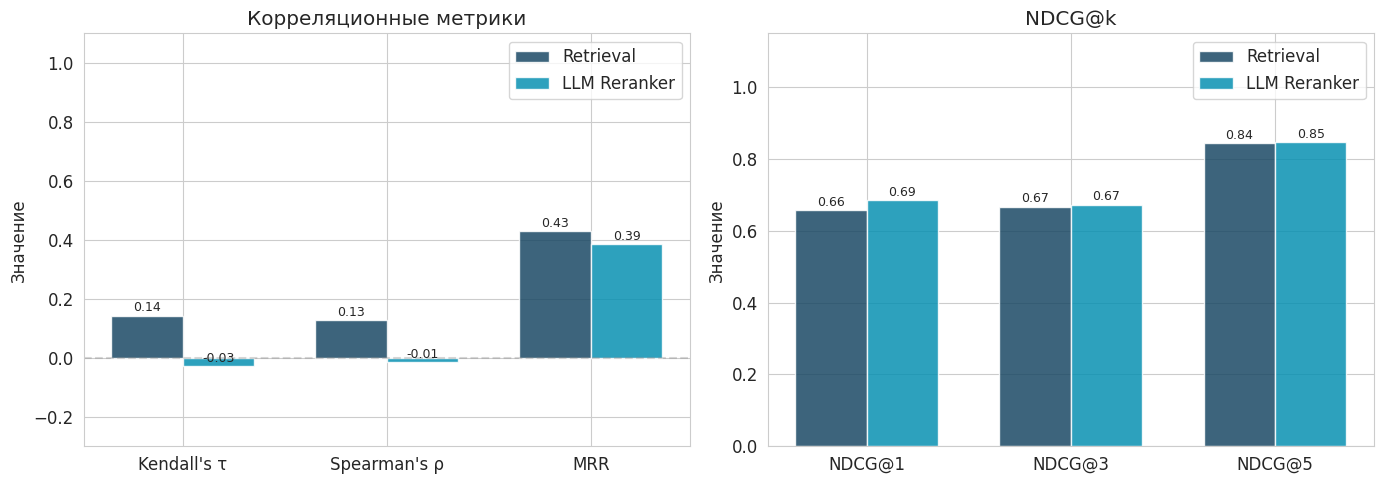

In [ ]:
def plot_metrics_comparison(metrics_retrieval, metrics_reranker):
    """Строит графики сравнения метрик."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Корреляционные метрики
    corr_metrics = ["kendall_tau", "spearman_rho", "mrr"]
    corr_labels = ["Kendall's τ", "Spearman's ρ", "MRR"]

    x = np.arange(len(corr_labels))
    width = 0.35

    vals_ret = [metrics_retrieval[m] if metrics_retrieval else 0 for m in corr_metrics]
    bars1 = axes[0].bar(x - width/2, vals_ret, width, label='Retrieval',
                        color='#1B4965', alpha=0.85)

    if metrics_reranker:
        vals_rer = [metrics_reranker[m] for m in corr_metrics]
        bars2 = axes[0].bar(x + width/2, vals_rer, width, label='LLM Reranker',
                            color='#0891B2', alpha=0.85)

    axes[0].set_ylabel('Значение')
    axes[0].set_title('Корреляционные метрики')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(corr_labels)
    axes[0].legend()
    axes[0].set_ylim(-0.3, 1.1)
    axes[0].axhline(y=0, color='gray', linestyle='--', alpha=0.3)

    # Значения на барах
    for bar in bars1:
        h = bar.get_height()
        axes[0].annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                         xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)
    if metrics_reranker:
        for bar in bars2:
            h = bar.get_height()
            axes[0].annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                             xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)

    # 2. NDCG метрики
    ndcg_metrics = ['ndcg@1', 'ndcg@3', 'ndcg@5']
    ndcg_labels = ['NDCG@1', 'NDCG@3', 'NDCG@5']

    x2 = np.arange(len(ndcg_labels))
    vals_ret2 = [metrics_retrieval[m] if metrics_retrieval else 0 for m in ndcg_metrics]
    bars3 = axes[1].bar(x2 - width/2, vals_ret2, width, label='Retrieval',
                        color='#1B4965', alpha=0.85)

    if metrics_reranker:
        vals_rer2 = [metrics_reranker[m] for m in ndcg_metrics]
        bars4 = axes[1].bar(x2 + width/2, vals_rer2, width, label='LLM Reranker',
                            color='#0891B2', alpha=0.85)

    axes[1].set_ylabel('Значение')
    axes[1].set_title('NDCG@k')
    axes[1].set_xticks(x2)
    axes[1].set_xticklabels(ndcg_labels)
    axes[1].legend()
    axes[1].set_ylim(0, 1.15)

    for bar in bars3:
        h = bar.get_height()
        axes[1].annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                         xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)
    if metrics_reranker:
        for bar in bars4:
            h = bar.get_height()
            axes[1].annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                             xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)

    plt.tight_layout()
    plt.savefig('metrics_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()


if metrics_retrieval:
    plot_metrics_comparison(metrics_retrieval, metrics_reranker)
else:
    print('Нет данных для визуализации')

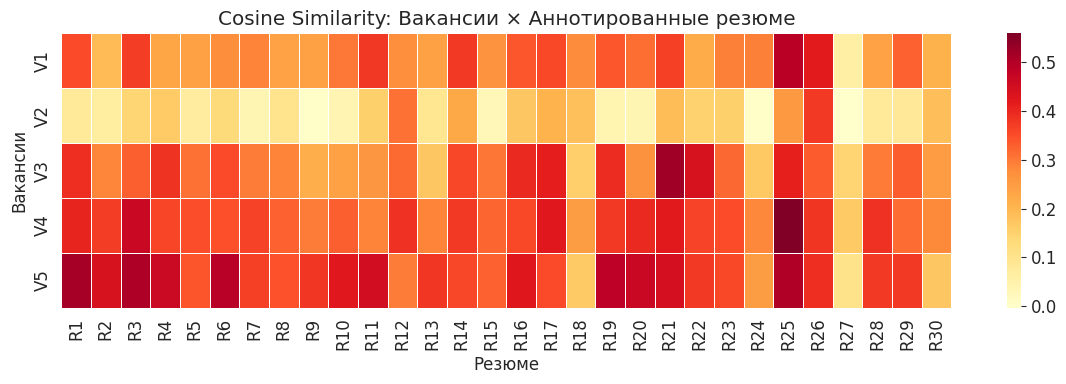

In [ ]:
# Heatmap: Retrieval scores по парам (вакансия x резюме)
def plot_similarity_heatmap(vacancy_texts, resume_embeddings, vacancy_embeddings,
                            resume_ids, title='Cosine Similarity: Вакансии × Резюме'):
    vids = sorted(vacancy_texts.keys())
    rids = sorted(resume_ids)

    sim_matrix = np.zeros((len(vids), len(rids)))
    for i, vid in enumerate(vids):
        for j, rid in enumerate(rids):
            if rid in resume_embeddings:
                sim_matrix[i, j] = float(np.dot(vacancy_embeddings[vid], resume_embeddings[rid]))

    fig, ax = plt.subplots(figsize=(max(12, len(rids) * 0.4), 4))
    sns.heatmap(sim_matrix, ax=ax, cmap='YlOrRd',
                xticklabels=[f'R{r}' for r in rids],
                yticklabels=[f'V{v}' for v in vids],
                annot=len(rids) <= 20,
                fmt='.2f' if len(rids) <= 20 else '',
                linewidths=0.5)
    ax.set_title(title)
    ax.set_xlabel('Резюме')
    ax.set_ylabel('Вакансии')
    plt.tight_layout()
    plt.savefig('similarity_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

# Heatmap для аннотированных резюме
plot_similarity_heatmap(vacancy_texts, resume_embeddings, vacancy_embeddings,
                        list(resumes_annotated.keys()),
                        title='Cosine Similarity: Вакансии × Аннотированные резюме')

## 18. Результаты для неаннотированных резюме (31-65)

Применяем пайплайн к неразмеченным резюме — демонстрация масштабируемости.

In [ ]:
# Retrieval для неаннотированных
unannotated_results = {}

for rid in sorted(resumes_unannotated.keys()):
    ranking = rank_vacancies_by_retrieval(rid)
    unannotated_results[rid] = {'retrieval': ranking}

# LLM Reranking для выборки (первые 5, чтобы не тратить много API)
if USE_LLM:
    log_info('RERANK', 'Реранжирование выборки неаннотированных резюме...')
    sample_rids = sorted(resumes_unannotated.keys())[:5]

    for rid in tqdm(sample_rids, desc='LLM Reranking (unannotated)'):
        prompt = build_reranker_prompt(rid, all_resumes[rid], vacancy_texts)
        scores = call_llm_reranker(prompt)
        if scores:
            sorted_vids = sorted(scores.keys(), key=lambda v: scores[v], reverse=True)
            unannotated_results[rid]['reranker'] = sorted_vids
            unannotated_results[rid]['scores'] = scores
        time.sleep(0.5)

# Показываем результаты
print('\n Результаты для неаннотированных резюме (топ-5 вакансий):')
print(f'{"Резюме":>8} | {"Retrieval":>20} | {"LLM Reranker":>20}')
print('-' * 55)

for rid in sorted(unannotated_results.keys())[:10]:
    ret = unannotated_results[rid].get('retrieval', [])
    rer = unannotated_results[rid].get('reranker', [])
    rer_str = str(rer) if rer else 'N/A'
    print(f'  #{rid:>4}  | {str(ret):>20} | {rer_str:>20}')

LLM Reranking (unannotated):   0%|          | 0/5 [00:00<?, ?it/s]


 Результаты для неаннотированных резюме (топ-5 вакансий):
  Резюме |            Retrieval |         LLM Reranker
-------------------------------------------------------
  #  31  |      [5, 3, 4, 1, 2] |      [5, 3, 4, 2, 1]
  #  32  |      [4, 1, 5, 3, 2] |      [3, 4, 5, 1, 2]
  #  33  |      [4, 3, 2, 5, 1] |      [3, 4, 5, 2, 1]
  #  34  |      [5, 3, 4, 1, 2] |      [4, 3, 5, 2, 1]
  #  35  |      [5, 4, 1, 3, 2] |      [5, 3, 2, 1, 4]
  #  36  |      [1, 5, 3, 4, 2] |                  N/A
  #  37  |      [4, 5, 3, 1, 2] |                  N/A
  #  38  |      [3, 5, 1, 4, 2] |                  N/A
  #  39  |      [3, 5, 4, 1, 2] |                  N/A
  #  40  |      [5, 4, 3, 1, 2] |                  N/A


## 19. Сохранение результатов

In [ ]:
# Сохраняем результаты в CSV
results_rows = []
for rid in sorted(all_resumes.keys()):
    row = {'resume_id': rid}

    # Ground truth
    gt = ground_truth.get(rid)
    if gt:
        row['gt_ranking'] = str(gt)
        row['gt_best_vacancy'] = gt[0]

    # Retrieval
    ret = retrieval_rankings.get(rid) or unannotated_results.get(rid, {}).get('retrieval')
    if ret:
        row['retrieval_ranking'] = str(ret)
        row['retrieval_best_vacancy'] = ret[0]

    # Reranker
    rer = reranker_rankings.get(rid) or unannotated_results.get(rid, {}).get('reranker')
    if rer:
        row['reranker_ranking'] = str(rer)
        row['reranker_best_vacancy'] = rer[0]

    # Scores
    scores = reranker_scores_raw.get(rid) or unannotated_results.get(rid, {}).get('scores')
    if scores:
        for vid, s in scores.items():
            row[f'llm_score_v{vid}'] = s

    results_rows.append(row)

results_df = pd.DataFrame(results_rows)
output_path = os.path.join(DATA_FOLDER, 'pipeline_results.csv')
results_df.to_csv(output_path, index=False, encoding='utf-8')
print(f' Результаты сохранены в: {output_path}')
display(results_df.head(10))

 Результаты сохранены в: /content/drive/MyDrive/vacancy-resume-matching-dataset/pipeline_results.csv


,resume_id,gt_ranking,gt_best_vacancy,retrieval_ranking,retrieval_best_vacancy,reranker_ranking,reranker_best_vacancy,llm_score_v1,llm_score_v2,llm_score_v3,llm_score_v4,llm_score_v5
0,1,"[4, 2, 3, 5, 1]",4.0,"[5, 4, 3, 1, 2]",5,"[5, 3, 4, 1, 2]",5.0,45.0,35.0,75.0,55.0,85.0
1,2,"[1, 4, 5, 2, 3]",1.0,"[5, 4, 3, 1, 2]",5,"[5, 3, 4, 2, 1]",5.0,25.0,45.0,75.0,60.0,85.0
2,3,"[1, 5, 4, 2, 3]",1.0,"[5, 4, 1, 3, 2]",5,"[4, 5, 3, 1, 2]",4.0,45.0,35.0,75.0,85.0,80.0
3,4,"[5, 1, 4, 2, 3]",5.0,"[5, 3, 4, 1, 2]",5,"[5, 3, 4, 2, 1]",5.0,35.0,45.0,75.0,60.0,85.0
4,5,"[1, 2, 4, 5, 3]",1.0,"[4, 5, 3, 1, 2]",4,"[5, 4, 3, 2, 1]",5.0,25.0,45.0,75.0,85.0,90.0
5,6,NaN,NaN,"[5, 3, 4, 1, 2]",5,"[5, 3, 1, 4, 2]",5.0,75.0,65.0,80.0,70.0,85.0
6,7,NaN,NaN,"[5, 4, 3, 1, 2]",5,"[1, 4, 5, 3, 2]",1.0,75.0,45.0,60.0,70.0,65.0
7,8,NaN,NaN,"[5, 4, 3, 1, 2]",5,"[5, 3, 2, 1, 4]",5.0,25.0,30.0,45.0,20.0,55.0
8,9,NaN,NaN,"[5, 4, 1, 3, 2]",5,"[4, 1, 5, 2, 3]",4.0,65.0,45.0,40.0,75.0,50.0
9,10,NaN,NaN,"[5, 4, 1, 3, 2]",5,"[4, 5, 1, 2, 3]",4.0,25.0,20.0,15.0,75.0,30.0
